In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display
import time

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from decimal import Decimal, ROUND_HALF_UP
from sklearn.linear_model import LassoCV
from sklearn.metrics import r2_score
import sys
from statsmodels.stats import weightstats
from statsmodels.stats import multitest as multi
import matplotlib.lines as mlines


from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor

imputer = IterativeImputer(
    estimator=RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)
)

import arivale_data_interface as adi
adi.apply_isb_config()

In [2]:
### Helpful functions
def report_na(df, axis=0, perc=True):
    """Reports on the `NaN`s of a vectorized dataframe
    :func:`DataInterface.get_data(vectorize = True)
            <analytics.data.datainterface.DataInterface.get_data>`
    Args:
        df (pandas.DataFrame): a vectorized dataframe
        axis (int): count by rows(1) or columns(0)
        perc (bool): return as percentage[Default: True] or count
    Returns:
        pandas.Series: the count or percent of NaNs for the given axis
    Notes:
        An example of how one might look at this result is:
        >>> import seaborn as sns
        >>> import matplotlib.pyplot as plt
        >>> sns.countplot(report_na(chemd['real'], axis=0))
        >>> plt.xticks(rotation=25)
    """
    if perc:
        return df.apply(lambda x: sum(x.isnull())/float(len(x)), axis=axis)
    else:
        return df.apply(lambda x: sum(x.isnull()), axis=axis)
    

def clean_NAs(df, percentage=0.10):
    # Keep labs with low percentage of NAs
    col_perc = report_na(df, axis=0)
    keep_labs = col_perc[col_perc <= percentage].index
    df_keep = df[keep_labs]

    # Keep patients with most values not na
    row_perc = report_na(df, axis=1)
    keep_labs = row_perc[row_perc <= percentage].index
    df_labs = df_keep.loc[keep_labs]
    return(df_labs)

In [3]:
# Load the data and the participants
# file locations
# data_file = '/shared-data/snapshots/arivale_snapshot_ISB_2019-05-10_0053/'

# add the data location to the file names
participants =  pd.read_csv("../data/abx_recency_covariates_all.csv", dtype={'public_client_id': str})
participants = participants[["public_client_id","days_in_program","sex", "age", "BMI_CALC"]].copy()

mets = adi.get_snapshot("metabolomics_corrected").sort_values(by="days_in_program")
misanns_ids = {'100020423':'100022485',
               '100020419':'100022482',
               '100020425':'100022480',
               '100020427':'100022479'}
mets = mets.rename(misanns_ids, axis='columns')

metabolite_features = mets.columns[8:]
mets.days_in_program = mets.days_in_program.astype("float64")

In [4]:
participants=participants.sort_values(by='days_in_program')
mets=mets.sort_values(by='days_in_program')

met_ids = pd.merge_asof(
    participants, mets, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest", 
    tolerance=30.0).dropna(subset=metabolite_features, how="all")
met_ids

,public_client_id,days_in_program,sex,age,BMI_CALC,sample_id,days_since_first_call,days_since_first_draw,month,weekday,...,999953114,999953157,999953172,999953266,999953267,999954831,999954832,999954834,999954839,999954840
3,01601230,-5.0,M,45.0,26.120098,A904AZ349-002,2.0,0.0,Jul,Thu,...,0.736626,1.928746,NaN,1.151177,0.899924,0.982119,0.992174,1.020387,0.369896,1.418072
4,01684342,-5.0,M,32.0,22.668163,A904AZ379-002,2.0,0.0,Jul,Wed,...,0.452953,NaN,NaN,1.864759,1.299824,1.037411,1.049852,1.109848,NaN,0.789232
5,01324699,-2.0,M,36.0,25.381075,A000AV155-002,0.0,0.0,Dec,Wed,...,0.714330,0.749277,0.910968,2.190841,1.156268,0.941816,0.736709,0.773792,1.650485,1.782973
6,01789632,-1.0,F,68.0,22.494537,A715AY425-002,-11.0,0.0,Apr,Fri,...,0.649365,0.882981,NaN,NaN,1.404256,0.987746,1.037036,0.877633,NaN,0.826977
7,01994483,0.0,M,28.0,24.363579,A972BH516-002,13.0,0.0,May,Wed,...,1.092669,0.894790,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.782441
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2628,01065944,134.0,F,56.0,25.505241,A196AX878-002,-21.0,0.0,Mar,Thu,...,1.867271,1.045174,0.992197,0.754807,1.127037,1.056790,1.139174,1.147004,0.460187,0.540622
2630,01129614,141.0,F,45.0,42.928834,A000BM839-002,119.0,0.0,Mar,Thu,...,NaN,0.873324,NaN,NaN,0.696875,NaN,NaN,NaN,NaN,NaN
2637,01282093,179.0,F,37.0,25.401367,A097BM200-002,-23.0,0.0,Mar,Wed,...,NaN,0.265486,0.685333,NaN,0.977107,NaN,NaN,NaN,NaN,NaN
2651,01448060,373.0,M,58.0,26.605753,A495BS036-003,NaN,357.0,Apr,Mon,...,NaN,1.233846,NaN,0.416939,1.556396,NaN,NaN,NaN,NaN,NaN


In [5]:
met_ids.rename(
    columns= dict(zip(
        metabolite_features,
        "metabolite_" + metabolite_features)),
    inplace=True)

In [6]:
mets_meta = pd.read_csv("../data/metabolites_snapshot_updated.csv")
mets_meta.index = map(str, mets_meta['feature'])
met_ids.columns = ([x if x not in mets_meta.index else "%s" % 
                 (mets_meta.loc[x, 'CHEMICAL_NAME']) for x in met_ids.columns])

In [7]:
met_ids.public_client_id.nunique()

1599

In [8]:
met_ids.set_index("public_client_id", inplace=True)

In [9]:
mets_ids_imputed = met_ids.iloc[:, 10:].reset_index()

In [10]:
mets_ids_imputed.sort_values(by='public_client_id')

,public_client_id,S-1-pyrroline-5-carboxylate,spermidine,1-methylnicotinamide,"12,13-DiHOME",5-hydroxyindoleacetate,alpha-ketoglutarate,kynurenate,3-hydroxyisobutyrate,3-hydroxy-3-methylglutarate,...,X - 24686,X - 24728,X - 24736,X - 24747,X - 24748,X - 24803,X - 24804,X - 24806,X - 24811,X - 24812
330,01001621,2.540378,0.568236,1.328050,NaN,1.003031,1.366908,0.967574,1.957150,0.928533,...,2.198704,1.036609,2.861960,0.980013,1.245966,NaN,NaN,NaN,NaN,NaN
942,01002183,0.528804,2.260729,0.425073,2.299795,1.940374,0.850577,1.737810,NaN,2.335956,...,0.772146,3.109291,1.689441,0.923594,0.896029,0.915957,0.859884,0.862706,0.364450,0.932469
1167,01002412,0.863152,0.535317,1.008430,1.300685,1.223568,0.877139,0.772371,1.052063,1.128991,...,0.725215,1.702258,1.155391,1.151021,NaN,0.913408,0.886259,NaN,0.214291,0.639387
1326,01002471,2.064995,NaN,1.308322,0.773852,NaN,0.760033,1.120927,0.864391,0.303651,...,NaN,0.865380,NaN,NaN,1.153715,NaN,NaN,NaN,NaN,NaN
363,01003555,0.713570,0.897179,0.976676,0.820367,0.964477,1.964455,1.415588,0.843104,1.389681,...,1.126584,1.009515,0.361973,0.995222,1.041174,NaN,NaN,NaN,4.468480,1.781095
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1034,01995874,1.594734,0.927024,1.863595,1.210643,2.309690,1.172326,1.221011,1.523600,1.339584,...,2.106039,1.355943,0.690967,0.990767,1.115116,1.042966,0.969554,0.986455,2.467022,1.170937
15,01997508,1.054860,0.415687,1.284647,1.041632,NaN,1.098982,1.422799,1.065390,0.998798,...,0.622458,0.615135,1.017328,1.305192,0.876478,0.863283,0.677948,0.703108,0.353758,0.791621
913,01997759,NaN,NaN,1.035167,1.169043,NaN,0.971747,1.121203,0.576222,1.206861,...,NaN,NaN,NaN,NaN,0.444542,NaN,NaN,NaN,NaN,0.636772
653,01997909,0.887345,NaN,1.264662,1.398818,0.385638,0.918802,1.412575,0.482770,0.739884,...,0.969291,1.976054,1.279032,1.741998,0.924345,0.969095,0.983454,0.966224,0.841450,0.689870


In [11]:
drop_nans = mets_ids_imputed.columns[mets_ids_imputed.isna().all()].tolist()

In [12]:
align = mets_ids_imputed.drop(columns=drop_nans).columns.tolist()

In [13]:
#mets_ids_imputed.to_csv("mets_ids_imputed.csv", index=False)
og_col_names = mets_ids_imputed.columns

In [14]:
### RUN R NOTEBOOK ###

In [15]:
mets_ids_imputed = pd.read_csv("mets_ids_imputed_missForest.csv", dtype={'public_client_id': str})

In [16]:
public_client_ids = mets_ids_imputed['public_client_id']
mets_ids_imputed = np.log(mets_ids_imputed.drop(columns='public_client_id'))
mets_ids_imputed.insert(0, 'public_client_id', public_client_ids)

In [17]:
mets_ids_imputed.columns = align

In [18]:
coeffs = pd.read_excel("../data/metBMI_SupplementaryData3.xlsx", sheet_name='MetBMImodel')

In [19]:
# model columns
model_cols = [f'Model_{i:02d}' for i in range(1, 11)]

# Get intercepts and bets
intercepts = coeffs[coeffs['Variable'] == 'Intercept'][model_cols].copy()
intercepts.index = ['Intercept']

betas = coeffs[coeffs['Variable'] != 'Intercept'].copy()
betas = betas.set_index('Variable')[model_cols]

orgin_met_cols = [col for col in mets_ids_imputed.columns
                  if col in betas.index and col != 'public_client_id']

In [20]:
orgin_mets = pd.read_csv("210104_Biological-BMI-paper_RF-imputation_baseline-metDF-with-RF-imputation.tsv",
                         sep='\t', 
                         converters={'public_client_id': str})

In [21]:
# Scale from original data
scaler = StandardScaler()
scaler.fit(orgin_mets[orgin_met_cols])

X_scaled = pd.DataFrame(
    scaler.transform(mets_ids_imputed[orgin_met_cols]),
    columns=orgin_met_cols,
    index=mets_ids_imputed.index
)
# dummy intercept to be updated
X_scaled['Intercept'] = 1.0

In [22]:
betas_with_intercept = pd.concat([betas.loc[orgin_met_cols], intercepts])

assert list(X_scaled.columns) == list(betas_with_intercept.index), \
    "Column mismatch between data and coefficients!"

In [23]:
predictions = np.dot(X_scaled, betas_with_intercept)

pred_df = pd.DataFrame(
    predictions,
    index=mets_ids_imputed.index,
    columns=model_cols
)

pred_df['log_bBMI_mean'] = pred_df.mean(axis=1)
pred_df['bBMI'] = np.e ** pred_df['log_bBMI_mean']

In [24]:
pred_df.insert(0, 'public_client_id', mets_ids_imputed['public_client_id'].values)

<Axes: >

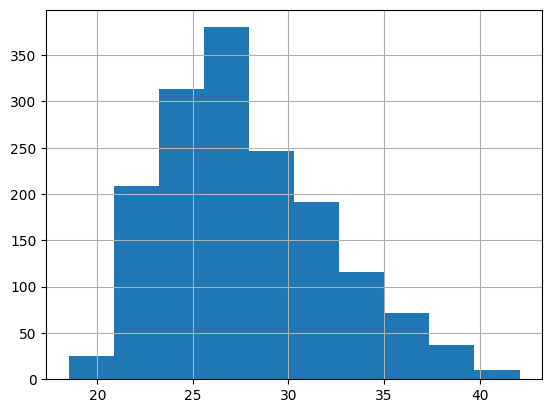

In [25]:
pred_df.bBMI.hist()

In [26]:
pred_df.to_csv("../data/metBMI_for_ids_crystal.csv", index=False)

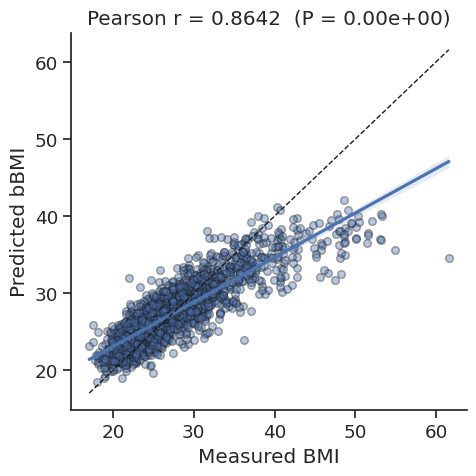

In [29]:
met_ids.reset_index(inplace=True)
pred_df['public_client_id'] = pred_df['public_client_id'].astype(str).str.zfill(8)
# met_ids['public_client_id'] = met_ids['public_client_id'].astype(str).str.zfill(8)

compare_bmi = pred_df[['public_client_id', 'bBMI']].merge(
    met_ids[['public_client_id', 'BMI_CALC']],
    on='public_client_id'
).dropna()

r, p = stats.pearsonr(compare_bmi['BMI_CALC'], compare_bmi['bBMI'])

sns.set(style='ticks', font_scale=1.2)
fig, ax = plt.subplots(figsize=(5, 5))
sns.regplot(data=compare_bmi, x='BMI_CALC', y='bBMI',
            scatter_kws={'alpha': 0.4, 'edgecolor': 'k', 's': 30}, ax=ax)
lims = [compare_bmi[['BMI_CALC', 'bBMI']].min().min(),
        compare_bmi[['BMI_CALC', 'bBMI']].max().max()]
ax.plot(lims, lims, 'k--', linewidth=1)
ax.set_xlabel('Measured BMI')
ax.set_ylabel('Predicted bBMI')
ax.set_title(f'Pearson r = {r:.4f}  (P = {p:.2e})')
sns.despine()
plt.tight_layout()
plt.show()

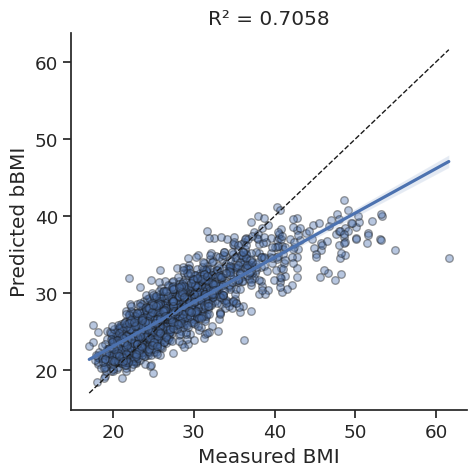

In [30]:
from sklearn.metrics import r2_score

r2 = r2_score(compare_bmi['BMI_CALC'], compare_bmi['bBMI'])

fig, ax = plt.subplots(figsize=(5, 5))
sns.regplot(data=compare_bmi, x='BMI_CALC', y='bBMI',
            scatter_kws={'alpha': 0.4, 'edgecolor': 'k', 's': 30}, ax=ax)
lims = [compare_bmi[['BMI_CALC', 'bBMI']].min().min(),
        compare_bmi[['BMI_CALC', 'bBMI']].max().max()]
ax.plot(lims, lims, 'k--', linewidth=1)
ax.set_xlabel('Measured BMI')
ax.set_ylabel('Predicted bBMI')
ax.set_title(f'R² = {r2:.4f}')
sns.despine()
plt.tight_layout()
plt.show()